# 07 - Structural Variant Machine Learning Models & Benchmark
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  
**Author**: Data Science & Genomics Team  
**Date**: August 2026

## Objective
Train and evaluate 4 machine learning model architectures on leakage-free chromosomal splits:
1. **Logistic Regression** (L2-regularized baseline)
2. **Random Forest** (Ensemble baseline)
3. **LightGBM** (Gradient boosted trees with class balancing)
4. **XGBoost** (Gradient boosted trees with PR-AUC optimization)

Evaluate on holdout chromosomes (Chr 19–22, X, Y) across PR-AUC, ROC-AUC, F1-Score, Brier Calibration Score, and Precision@Top-5%.


In [1]:
import os

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_recall_curve, auc, roc_curve, roc_auc_score,
    f1_score, balanced_accuracy_score, brier_score_loss
)
from sklearn.calibration import calibration_curve
import xgboost as xgb
import lightgbm as lgb

sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

train_path = resolve_path("processed/train.csv.gz")
val_path = resolve_path("processed/val.csv.gz")
test_path = resolve_path("processed/test.csv.gz")

df_train = pd.read_csv(train_path)
df_val = pd.read_csv(val_path)
df_test = pd.read_csv(test_path)

exclude_cols = ["variation_id", "chrom", "start", "stop", "clinical_class", "assembly", "target"]
feature_cols = [c for c in df_train.columns if c not in exclude_cols]

X_train, y_train = df_train[feature_cols], df_train["target"].to_numpy()
X_val, y_val = df_val[feature_cols], df_val["target"].to_numpy()
X_test, y_test = df_test[feature_cols], df_test["target"].to_numpy()

print("Dataset Partitions:")
print(f"  Train (Chr 1-14):      {X_train.shape[0]:,} SVs ({y_train.mean()*100:.1f}% Pathogenic)")
print(f"  Val   (Chr 15-18):     {X_val.shape[0]:,} SVs ({y_val.mean()*100:.1f}% Pathogenic)")
print(f"  Test  (Chr 19-22,X,Y): {X_test.shape[0]:,} SVs ({y_test.mean()*100:.1f}% Pathogenic)")
print(f"  Feature Count:         {len(feature_cols)} features")


Dataset Partitions:
  Train (Chr 1-14):      25,158 SVs (78.5% Pathogenic)
  Val   (Chr 15-18):     8,546 SVs (86.6% Pathogenic)
  Test  (Chr 19-22,X,Y): 8,854 SVs (82.8% Pathogenic)
  Feature Count:         24 features


## 1. Train Baseline & Advanced Models

In [2]:
# 1. Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

# 2. Random Forest
rf = RandomForestClassifier(n_estimators=150, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

# 3. LightGBM
lgb_train = lgb.Dataset(X_train, label=y_train)
lgb_val = lgb.Dataset(X_val, label=y_val, reference=lgb_train)
lgb_params = {
    "objective": "binary", "metric": "binary_logloss", "is_unbalance": True,
    "learning_rate": 0.05, "num_leaves": 31, "feature_fraction": 0.85,
    "verbose": -1, "random_state": 42
}
lgb_model = lgb.train(lgb_params, lgb_train, num_boost_round=300, valid_sets=[lgb_train, lgb_val])

# 4. XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    scale_pos_weight=scale_pos, subsample=0.85, colsample_bytree=0.85,
    eval_metric="aucpr", random_state=42
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

print("All 4 models trained successfully.")


All 4 models trained successfully.


## 2. Model Performance Evaluation Table on Holdout Test Set

In [3]:
models = {
    "Logistic Regression": lr.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": rf.predict_proba(X_test)[:, 1],
    "LightGBM": lgb_model.predict(X_test),
    "XGBoost": xgb_model.predict_proba(X_test)[:, 1]
}

eval_rows = []
for name, y_prob in models.items():
    p, r, thresh_pr = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(r, p)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    f1_scores = 2 * (p * r) / (p + r + 1e-9)
    best_idx = np.argmax(f1_scores)
    best_f1 = f1_scores[best_idx]
    best_thresh = thresh_pr[best_idx] if best_idx < len(thresh_pr) else 0.5
    
    y_pred_opt = (y_prob >= best_thresh).astype(int)
    bal_acc = balanced_accuracy_score(y_test, y_pred_opt)
    brier = brier_score_loss(y_test, y_prob)
    
    n_top5 = int(len(y_prob) * 0.05)
    p_at_5 = y_test[np.argsort(y_prob)[::-1][:n_top5]].mean()
    
    eval_rows.append({
        "Model": name,
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "F1-Score": round(best_f1, 4),
        "Brier Score": round(brier, 4),
        "Precision@Top-5%": f"{p_at_5*100:.1f}%",
        "Balanced Accuracy": round(bal_acc, 4)
    })

df_results = pd.DataFrame(eval_rows)
df_results


,Model,PR-AUC,ROC-AUC,F1-Score,Brier Score,Precision@Top-5%,Balanced Accuracy
0,Logistic Regression,0.9544,0.8411,0.9254,0.1755,99.8%,0.7264
1,Random Forest,0.9682,0.8807,0.9307,0.1570,99.1%,0.6917
2,LightGBM,0.9694,0.8876,0.9350,0.1641,98.9%,0.7284
3,XGBoost,0.9696,0.8883,0.9364,0.1649,98.9%,0.7306


## 3. Precision-Recall, ROC, and Calibration Curves

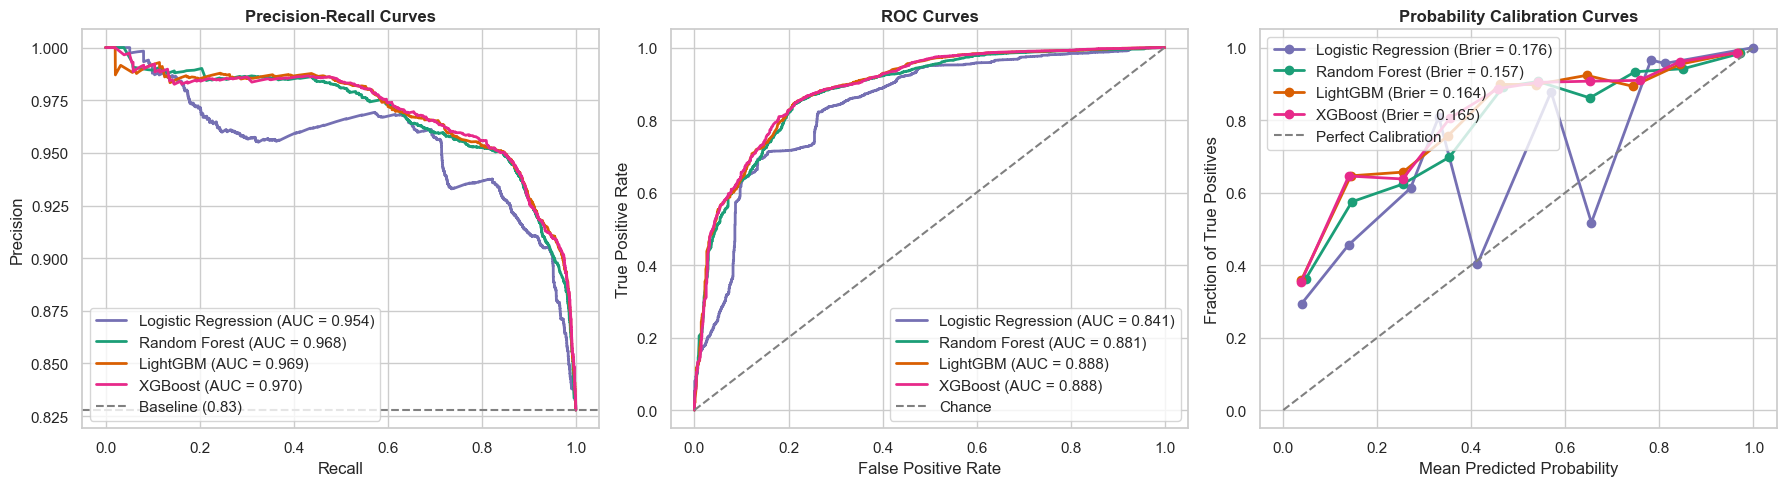

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"Logistic Regression": "#7570b3", "Random Forest": "#1b9e77", "LightGBM": "#d95f02", "XGBoost": "#e7298a"}

# 1. PR Curves
for name, y_prob in models.items():
    p, r, _ = precision_recall_curve(y_test, y_prob)
    axes[0].plot(r, p, label=f"{name} (AUC = {auc(r, p):.3f})", color=colors[name], linewidth=2)
axes[0].axhline(y=y_test.mean(), color="gray", linestyle="--", label=f"Baseline ({y_test.mean():.2f})")
axes[0].set_title("Precision-Recall Curves", fontweight="bold")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="lower left")

# 2. ROC Curves
for name, y_prob in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})", color=colors[name], linewidth=2)
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance")
axes[1].set_title("ROC Curves", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

# 3. Calibration Curves
for name, y_prob in models.items():
    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)
    axes[2].plot(prob_pred, prob_true, marker="o", label=f"{name} (Brier = {brier_score_loss(y_test, y_prob):.3f})", color=colors[name], linewidth=2)
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect Calibration")
axes[2].set_title("Probability Calibration Curves", fontweight="bold")
axes[2].set_xlabel("Mean Predicted Probability")
axes[2].set_ylabel("Fraction of True Positives")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()
